# Microsoft Phi-4 14B Zero-Shot Evaluation

## 1. Model & Experiment Overview

Microsoft Phi-4 (14B) generated an `ANSWERABLE` or `UNANSWERABLE` label for each math word problem. This notebook analyzes saved outputs from BF16 zero-shot inference with deterministic greedy decoding and a maximum of 16 new tokens. SUM Test is the held-out benchmark and UMWP is the external benchmark.

UMWP has two strict inference runs. `run_01` used the original frozen prompt. `run_02` removed the period after `UNANSWERABLE` in the label instruction. The modified prompt defines a separate experimental condition. SUM has a saved strict run for the modified prompt. Each `run_02_cleaned` CSV contains a researcher-initiated post-processing analysis of its corresponding `run_02` outputs.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'data/processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/llm/phi-4'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
DATASETS = {'sum': (10944, 'pair_id'), 'umwp': (5200, 'id')}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_predictions(dataset, run_id):
    path = RESULTS_DIR / dataset / run_id / 'predictions.csv'
    count, identifier = DATASETS[dataset]
    predictions = pd.read_csv(path, keep_default_na=False, dtype={identifier: str, 'raw_response': str})
    required = {'row_index', identifier, 'text', 'true_label', 'raw_response', 'prediction',
                'valid', 'generated_token_ids', 'hit_token_limit'}
    if (not required.issubset(predictions) or predictions['row_index'].tolist() != list(range(count))
            or predictions[identifier].eq('').any()
            or not predictions['true_label'].isin(LABELS).all()
            or not predictions['prediction'].isin(PREDICTED_LABELS).all()
            or not predictions['valid'].eq(predictions['prediction'].ne('INVALID')).all()):
        raise ValueError(f'{path}: unexpected prediction schema, coverage or labels')
    return predictions


def score_predictions(predictions):
    matrix = pd.crosstab(predictions['true_label'], predictions['prediction']).reindex(
        index=LABELS, columns=PREDICTED_LABELS, fill_value=0,
    )
    tn, fp, invalid_negative = matrix.iloc[0]
    fn, tp, invalid_positive = matrix.iloc[1]
    missed = fn + invalid_positive
    count = len(predictions)
    invalid = int(invalid_negative + invalid_positive)

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    return {
        'num_examples': count, 'num_invalid': invalid, 'invalid_rate': invalid / count,
        'accuracy': (tn + tp) / count,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
    }, matrix


def load_strict(dataset, run_id):
    directory = RESULTS_DIR / dataset / run_id
    predictions = load_predictions(dataset, run_id)
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    run = metrics['run']
    if (run['model_id'], run['dataset'], run['run_id'], metrics['positive_class']) != (
            'microsoft/phi-4', dataset, run_id, 'UNANSWERABLE'):
        raise ValueError(f'{directory}: unexpected model, run or positive class')
    parsed = predictions['raw_response'].str.strip()
    if not parsed.where(parsed.isin(LABELS), 'INVALID').eq(predictions['prediction']).all():
        raise ValueError(f'{directory}: recorded labels disagree with strict parsing')
    expected, matrix = score_predictions(predictions)
    saved_matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    if (list(saved_matrix.index) != LABELS or list(saved_matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS
            or saved_matrix.values.tolist() != matrix.values.tolist()
            or metrics['confusion_matrix'] != matrix.values.tolist()
            or run['row_count'] != len(predictions)):
        raise ValueError(f'{directory}: inconsistent confusion matrix or row count')
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with saved predictions')
    return metrics, matrix, predictions


def load_cleaned(dataset, strict_predictions):
    cleaned = load_predictions(dataset, 'run_02_cleaned')
    stable_columns = strict_predictions.columns.drop(['raw_response', 'prediction', 'valid'])
    if not cleaned[stable_columns].equals(strict_predictions[stable_columns]):
        raise ValueError(f'{dataset}: cleaned rows differ from their run_02 source')
    was_invalid = strict_predictions['prediction'].eq('INVALID')
    if not cleaned.loc[~was_invalid].equals(strict_predictions.loc[~was_invalid]):
        raise ValueError(f'{dataset}: cleaning changed a strict valid prediction')
    # Verify recorded cleaning against the first standalone label in the original text.
    first_label = strict_predictions.loc[was_invalid, 'raw_response'].str.extract(
        r'\b(UNANSWERABLE|ANSWERABLE)\b', expand=False,
    )
    if (first_label.isna().any()
            or not cleaned.loc[was_invalid, 'prediction'].eq(first_label).all()
            or not cleaned.loc[was_invalid, 'raw_response'].eq(first_label).all()):
        raise ValueError(f'{dataset}: cleaned values disagree with the original responses')
    metrics, matrix = score_predictions(cleaned)
    if metrics['num_invalid']:
        raise ValueError(f'{dataset}: expected no INVALID labels after cleaning')
    return metrics, matrix, cleaned


sum_strict = load_strict('sum', 'run_02')
sum_cleaned = load_cleaned('sum', sum_strict[2])
umwp_original = load_strict('umwp', 'run_01')
umwp_strict = load_strict('umwp', 'run_02')
umwp_cleaned = load_cleaned('umwp', umwp_strict[2])

In [2]:
settings = {
    'Model': 'model_id', 'Model type': 'model_type', 'Architecture': 'model_architectures',
    'Model API': 'model_api', 'Tokenizer API': 'tokenizer_api', 'Weights path': 'model_path',
    'Chat template': 'chat_template', 'Precision': 'dtype', 'Quantization': 'quantization',
    'GPU': 'gpu', 'Requested temperature': 'requested_temperature', 'Sampling enabled': 'do_sample',
    'Number of beams': 'num_beams', 'Maximum new tokens': 'max_new_tokens',
    'PyTorch': 'torch_version', 'Transformers': 'transformers_version', 'CUDA': 'cuda_version',
}
recorded_runs = {
    'SUM Test run_02': sum_strict[0]['run'],
    'UMWP run_01': umwp_original[0]['run'],
    'UMWP run_02': umwp_strict[0]['run'],
}
run = recorded_runs['UMWP run_02']
for key in (*settings.values(), 'model_sha256', 'shared_evaluator_sha256',
            'transformers_distribution_url', 'invalid_output_policy'):
    if any(record[key] != run[key] for record in recorded_runs.values()):
        raise ValueError(f'Saved runs disagree on {key}')

original_prompt = recorded_runs['UMWP run_01']['prompt']
modified_prompt = run['prompt']
old_line, new_line = '\nANSWERABLE or UNANSWERABLE.\n', '\nANSWERABLE or UNANSWERABLE\n'
if (original_prompt.count(old_line) != 1 or original_prompt.replace(old_line, new_line, 1) != modified_prompt
        or recorded_runs['SUM Test run_02']['prompt'] != modified_prompt
        or recorded_runs['UMWP run_01']['dataset_sha256'] != run['dataset_sha256']):
    raise ValueError('Saved prompt difference or UMWP dataset fingerprint is unexpected')

configuration = {label: 'None' if run[key] is None else str(run[key]) for label, key in settings.items()}
configuration['Decoding'] = 'Greedy' if not run['do_sample'] and run['num_beams'] == 1 else 'See settings'
vcs = (run['transformers_distribution_url'] or {}).get('vcs_info') or {}
configuration['Transformers source commit'] = vcs.get('commit_id', 'Unavailable')
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact original prompt (UMWP run_01)**\n\n```text\n' + original_prompt + '\n```'))
display(Markdown('**Only changed line in run_02**\n\n```diff\n-' + old_line.strip()
                 + '\n+' + new_line.strip() + '\n```'))

fingerprints = {
    'Model SHA-256': run['model_sha256'],
    'Shared evaluator SHA-256': run['shared_evaluator_sha256'],
    **{f'{name} evaluator SHA-256': record['evaluator_sha256'] for name, record in recorded_runs.items()},
    **{f'{name} dataset SHA-256': record['dataset_sha256'] for name, record in recorded_runs.items()},
}
display(pd.Series(fingerprints, name='Recorded value').rename_axis('Fingerprint').to_frame())

,Recorded setting
Setting,
Model,microsoft/phi-4
Model type,phi3
Architecture,['Phi3ForCausalLM']
Model API,Phi3ForCausalLM
Tokenizer API,AutoTokenizer
Weights path,models/phi-4
Chat template,"Standard Phi-4 native ChatML template, one unc..."
Precision,bfloat16
Quantization,None


**Exact original prompt (UMWP run_01)**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

**Only changed line in run_02**

```diff
-ANSWERABLE or UNANSWERABLE.
+ANSWERABLE or UNANSWERABLE
```

,Recorded value
Fingerprint,
Model SHA-256,ac83258b9494bc0aa13e21e33f1491ccf9eef30f13fdef...
Shared evaluator SHA-256,292e98e5db749939399e3fea2a6279fd99648160577d96...
SUM Test run_02 evaluator SHA-256,fb07da3fe702d01d5492403b15cbd8adf33a9acccd81d3...
UMWP run_01 evaluator SHA-256,2f4df5aba765fae4a18527c7421678d1cc3c34d5577800...
UMWP run_02 evaluator SHA-256,fb07da3fe702d01d5492403b15cbd8adf33a9acccd81d3...
SUM Test run_02 dataset SHA-256,c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...
UMWP run_01 dataset SHA-256,92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...
UMWP run_02 dataset SHA-256,92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...


## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

The strict parser evaluates output-format compliance as well as classification. After a label followed by an explanation fails exact matching, the additional post-processing analysis extracts the first valid label from the original response. The cleaned CSVs contain the resulting labels and may contain shortened response text. Examples and formatting counts below use the preserved strict CSVs. Cleaned metrics are recomputed from the saved cleaned predictions using the same class definitions and denominators.

In [3]:
policy = sum_strict[0]['invalid_output_policy']
if any(run[0]['invalid_output_policy'] != policy for run in (umwp_original, umwp_strict)):
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + policy))


def show_evaluation(name, metrics, matrix, *, cleaned=False):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.6f}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    if cleaned:
        matrix = matrix[LABELS]
    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def show_class_errors(matrix):
    support = matrix.sum(axis=1)
    correct = pd.Series([matrix.loc[label, label] for label in LABELS], index=LABELS)
    wrong_label = pd.Series(
        [matrix.loc[LABELS[0], LABELS[1]], matrix.loc[LABELS[1], LABELS[0]]],
        index=LABELS,
    )
    errors = pd.DataFrame({
        'Actual examples': support,
        'Correct': correct,
        'Wrong label': wrong_label,
        'INVALID': matrix['INVALID'],
        'Wrong-label rate': (wrong_label / support).map('{:.2%}'.format),
        'Total error rate': ((wrong_label + matrix['INVALID']) / support).map('{:.2%}'.format),
    })
    display(errors.rename_axis('Actual class'))


def interpret_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    support = matrix.sum(axis=1)
    return (
        f'There were **{fp:,} false positives** ({fp / support["ANSWERABLE"]:.2%} '
        f'of answerable questions) and **{fn:,} false negatives** '
        f'({fn / support["UNANSWERABLE"]:.2%} of unanswerable questions). '
        f'Of the true UNANSWERABLE rows, {matrix.loc["UNANSWERABLE", "INVALID"]:,} '
        'additionally received INVALID responses and count as missed positives in recall.'
    )


def show_examples(predictions, identifier):
    false_positives = predictions['true_label'].eq('ANSWERABLE') & predictions['prediction'].eq('UNANSWERABLE')
    false_negatives = predictions['true_label'].eq('UNANSWERABLE') & predictions['prediction'].eq('ANSWERABLE')
    categories = {
        'False positive': false_positives,
        'False negative': false_negatives,
        'INVALID': predictions['prediction'].eq('INVALID'),
    }
    columns = ['row_index', identifier, 'text', 'true_label', 'prediction', 'raw_response', 'hit_token_limit']
    examples = pd.concat(
        [predictions.loc[mask, columns].head(1).assign(error=label) for label, mask in categories.items()],
        ignore_index=True,
    )
    # repr keeps empty strings, trailing whitespace and newlines visible.
    examples['raw_response'] = examples['raw_response'].map(repr)
    if examples.empty:
        display(Markdown('No recorded errors in these categories.'))
    else:
        display(examples.set_index('error').rename_axis('Error type').rename(columns={
            'row_index': 'Row index', 'pair_id': 'Pair ID', 'id': 'Question ID',
            'text': 'Question', 'true_label': 'Actual label', 'prediction': 'Prediction',
            'raw_response': 'Raw response (repr)', 'hit_token_limit': 'Hit token limit',
        }))
    missing = [label for label, mask in categories.items() if not mask.any()]
    if missing:
        display(Markdown('**Categories with no recorded examples:** ' + ', '.join(missing) + '.'))


def show_run(name, evaluation, *, cleaned=False):
    metrics, matrix, _ = evaluation
    show_evaluation(name, metrics, matrix, cleaned=cleaned)
    show_class_errors(matrix)
    if not cleaned:
        display(Markdown(interpret_errors(matrix)))


def show_cleaning_effect(strict, cleaned):
    before, after = strict[2], cleaned[2]
    recovered = before['prediction'].eq('INVALID')
    correct = after['prediction'].eq(after['true_label'])
    display(Markdown(
        f'Post-processing assigned a label to **{recovered.sum():,}** originally INVALID responses. '
        f'Of these, **{(recovered & correct).sum():,}** matched the reference and '
        f'**{(recovered & ~correct).sum():,}** were wrong-label predictions.'
    ))

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test uses the complete saved modified-prompt `run_02`. The strict examples show the first recorded row per error category in evaluation order.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test run_02,"10,944",0.670139,0.846722,0.502741,0.630891,"1,683 (15.38%)"


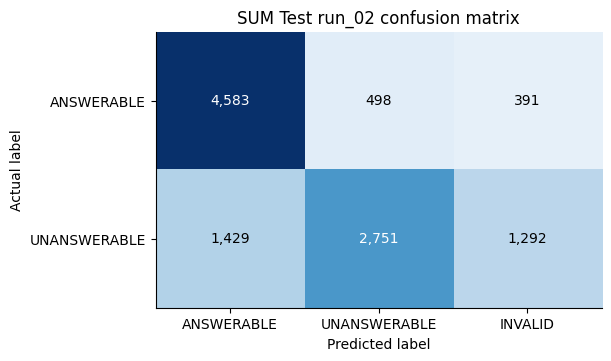

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,4583,498,391,9.10%,16.25%
UNANSWERABLE,5472,2751,1429,1292,26.11%,49.73%


There were **498 false positives** (9.10% of answerable questions) and **1,429 false negatives** (26.11% of unanswerable questions). Of the true UNANSWERABLE rows, 1,292 additionally received INVALID responses and count as missed positives in recall.

,Row index,Pair ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,36,22573,The total number of workers in Workshop A and ...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,21,36348,Triangles ABC and AEF are such that B is the m...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,6,13331,"Simplify first, then evaluate: \(\left(\frac{2...",UNANSWERABLE,INVALID,"'UNANSWERABLE\n\nThe set \\(\\{3, 3, '",True


In [4]:
show_run('SUM Test run_02', sum_strict)
show_examples(sum_strict[2], 'pair_id')

### Post-processed predictions

The cleaned CSV uses the same `run_02` questions and generations. It records the additional researcher-initiated label extraction.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test run_02_cleaned,"10,944",0.793037,0.830142,0.736842,0.780714,0 (0.00%)


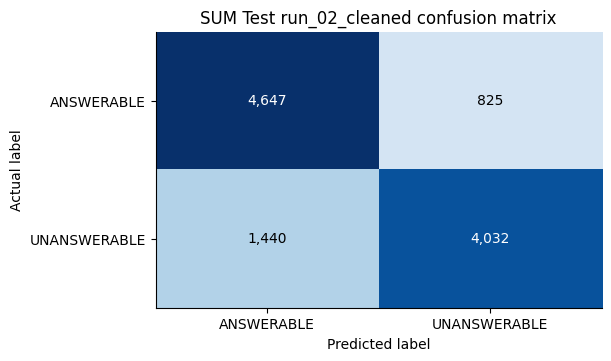

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,4647,825,0,15.08%,15.08%
UNANSWERABLE,5472,4032,1440,0,26.32%,26.32%


Post-processing assigned a label to **1,683** originally INVALID responses. Of these, **1,345** matched the reference and **338** were wrong-label predictions.

In [5]:
show_run('SUM Test run_02_cleaned', sum_cleaned, cleaned=True)
show_cleaning_effect(sum_strict, sum_cleaned)

## 4. UMWP Results & Analysis

UMWP uses the same external benchmark rows for both strict prompt variants. The strict examples follow the SUM selection rule.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP run_01,"5,200",0.485000,0.000000,0.000000,0.000000,"1,943 (37.37%)"


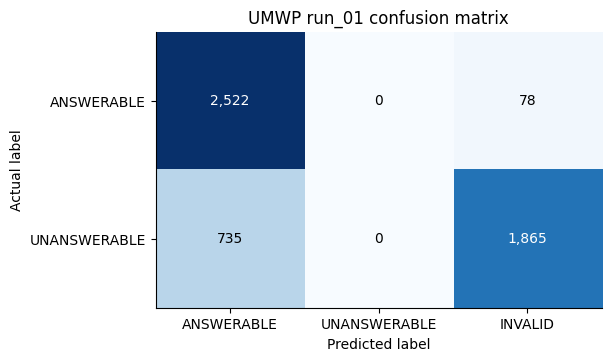

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2522,0,78,0.00%,3.00%
UNANSWERABLE,2600,0,735,1865,28.27%,100.00%


There were **0 false positives** (0.00% of answerable questions) and **735 false negatives** (28.27% of unanswerable questions). Of the true UNANSWERABLE rows, 1,865 additionally received INVALID responses and count as missed positives in recall.

**1,610 of 1,943 INVALID responses** were exactly `UNANSWERABLE.` after surrounding whitespace was trimmed. The period is part of the generated response and fails exact matching. The strict confusion matrix therefore records zero predictions of the exact `UNANSWERABLE` label in this run.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False negative,2602,2503,Randy has 58 blocks. He uses 27 blocks to buil...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,6,7,The Razorback shop makes $ 210 dollars off eac...,ANSWERABLE,INVALID,'UNANSWERABLE.',False


**Categories with no recorded examples:** False positive.

In [6]:
show_run('UMWP run_01', umwp_original)
strict_original = umwp_original[2]
period_only = strict_original['raw_response'].str.strip().eq('UNANSWERABLE.')
invalid = umwp_original[0]['num_invalid']
display(Markdown(
    f'**{period_only.sum():,} of {invalid:,} INVALID responses** were exactly `UNANSWERABLE.` '
    'after surrounding whitespace was trimmed. The period is part of the generated response '
    'and fails exact matching. The strict confusion matrix therefore records zero '
    'predictions of the exact `UNANSWERABLE` label in this run.'
))
show_examples(strict_original, 'id')

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP run_02,"5,200",0.816923,0.965188,0.661154,0.784752,115 (2.21%)


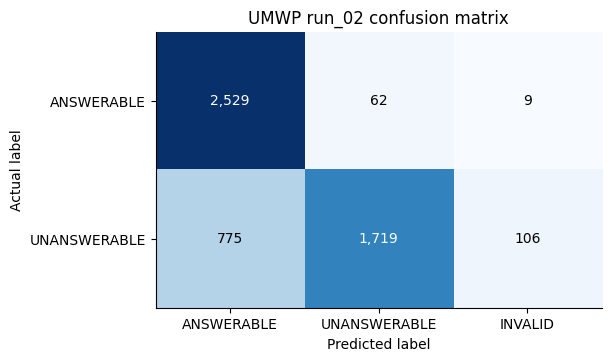

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2529,62,9,2.38%,2.73%
UNANSWERABLE,2600,1719,775,106,29.81%,33.88%


There were **62 false positives** (2.38% of answerable questions) and **775 false negatives** (29.81% of unanswerable questions). Of the true UNANSWERABLE rows, 106 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,6,7,The Razorback shop makes $ 210 dollars off eac...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,2602,2503,Randy has 58 blocks. He uses 27 blocks to buil...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,200,201,The school is planning a field trip. The schoo...,ANSWERABLE,INVALID,'UNANSWERABLE\n\nThe problem does not provide ...,True


In [7]:
show_run('UMWP run_02', umwp_strict)
show_examples(umwp_strict[2], 'id')

### Post-processed predictions

The cleaned UMWP CSV uses the modified-prompt generations. The original frozen-prompt run remains a separate strict comparison.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP run_02_cleaned,"5,200",0.837308,0.962553,0.701923,0.811833,0 (0.00%)


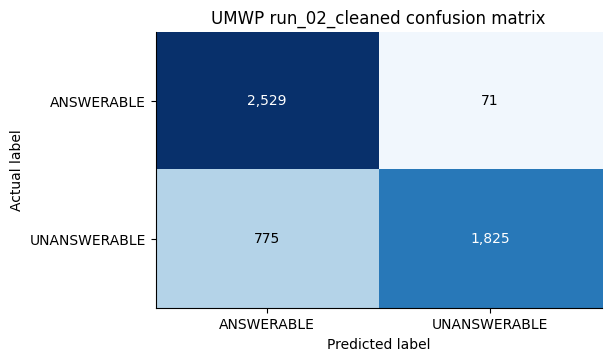

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2529,71,0,2.73%,2.73%
UNANSWERABLE,2600,1825,775,0,29.81%,29.81%


Post-processing assigned a label to **115** originally INVALID responses. Of these, **106** matched the reference and **9** were wrong-label predictions.

In [8]:
show_run('UMWP run_02_cleaned', umwp_cleaned, cleaned=True)
show_cleaning_effect(umwp_strict, umwp_cleaned)

## 5. Dataset Comparison & Interpretation

Accuracy, INVALID rate, and prediction shares use each run's full dataset as the denominator. Precision, recall, and F1 use UNANSWERABLE as the positive class. The comparisons keep the original prompt, modified prompt, and subsequent post-processing visible as separate conditions.

prediction,ANSWERABLE,UNANSWERABLE,INVALID
Dataset,,,
UMWP run_01,3257 (62.63%),0 (0.00%),1943 (37.37%)
UMWP run_02,3304 (63.54%),1781 (34.25%),115 (2.21%)
UMWP cleaned,3304 (63.54%),1896 (36.46%),0 (0.00%)
SUM run_02,6012 (54.93%),3249 (29.69%),1683 (15.38%)
SUM cleaned,6087 (55.62%),4857 (44.38%),0 (0.00%)


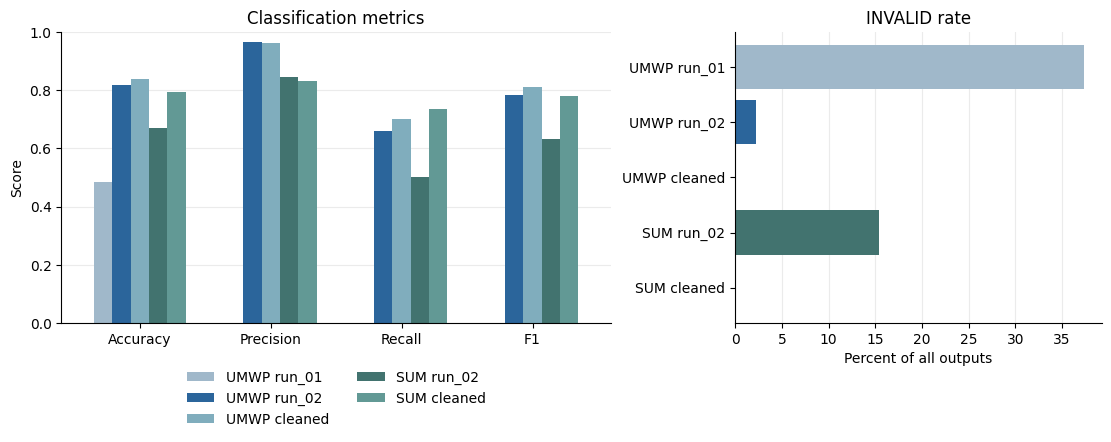

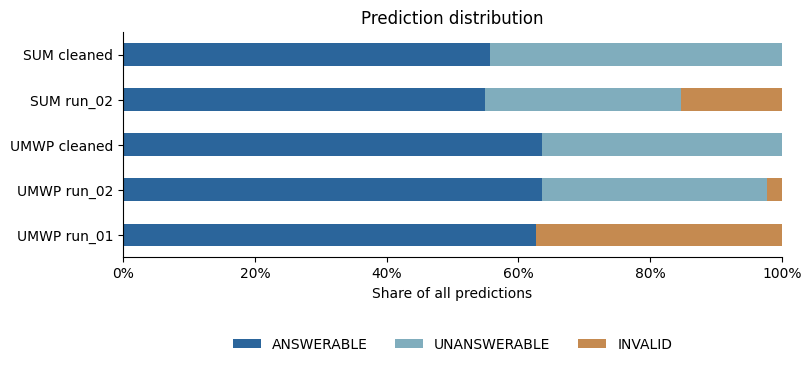

In [9]:
evaluations = {
    'UMWP run_01': umwp_original[:2],
    'UMWP run_02': umwp_strict[:2],
    'UMWP cleaned': umwp_cleaned[:2],
    'SUM run_02': sum_strict[:2],
    'SUM cleaned': sum_cleaned[:2],
}
metric_rates = pd.DataFrame({
    name: {label: metrics[key] for label, key in METRICS.items()}
    for name, (metrics, _) in evaluations.items()
})
metric_rates.index = ['Accuracy', 'Precision', 'Recall', 'F1']
invalid_rates = pd.Series({name: metrics['invalid_rate'] for name, (metrics, _) in evaluations.items()})
prediction_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, (_, matrix) in evaluations.items()
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
display((prediction_counts.astype(str) + ' (' + prediction_shares.map('{:.2%}'.format) + ')')
        .rename_axis('Dataset'))

colors = ['#a0b8ca', '#2b659b', '#80adbd', '#42736f', '#629995']
fig, (ax_metrics, ax_invalid) = plt.subplots(
    1, 2, figsize=(11, 4.3), width_ratios=[3, 2], layout='constrained',
)
metric_rates.plot.bar(ax=ax_metrics, color=colors, rot=0, width=0.7)
ax_metrics.set(ylim=(0, 1), ylabel='Score', title='Classification metrics')
ax_metrics.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax_invalid.barh(invalid_rates.index, invalid_rates * 100, color=colors)
ax_invalid.invert_yaxis()
ax_invalid.set(xlabel='Percent of all outputs', title='INVALID rate')
for ax in (ax_metrics, ax_invalid):
    ax.set_axisbelow(True)
    ax.grid(axis='y' if ax is ax_metrics else 'x', alpha=0.25)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.set(xlim=(0, 1), xlabel='Share of all predictions', ylabel='', title='Prediction distribution')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.show()
plt.close(fig)

In [10]:
original, modified, cleaned = (result[0] for result in (umwp_original, umwp_strict, umwp_cleaned))
sum_before, sum_after = sum_strict[0], sum_cleaned[0]
display(Markdown(
    f"- On the same UMWP rows, the modified prompt changed strict accuracy by "
    f"**{100 * (modified['accuracy'] - original['accuracy']):+.2f} percentage points** and "
    f"changed INVALID from **{original['num_invalid']:,}** to **{modified['num_invalid']:,}**. "
    "The modified-prompt run is a prompt-sensitivity result and should be compared separately "
    "from the original frozen-prompt runs of other models.\n"
    f"- Applying label extraction to the saved modified-prompt outputs changed accuracy by "
    f"**{100 * (cleaned['accuracy'] - modified['accuracy']):+.2f} percentage points** on UMWP "
    f"and **{100 * (sum_after['accuracy'] - sum_before['accuracy']):+.2f} percentage points** on SUM. "
    "The extraction was an additional researcher-initiated analysis outside the original protocol.\n"
    "- Exact-format compliance and classification correctness are distinct dimensions. "
    "Explanations reduce strict format compliance even when the response begins with the correct label. "
    "Recovering a label can also reveal a wrong classification."
))

- On the same UMWP rows, the modified prompt changed strict accuracy by **+33.19 percentage points** and changed INVALID from **1,943** to **115**. The modified-prompt run is a prompt-sensitivity result and should be compared separately from the original frozen-prompt runs of other models.
- Applying label extraction to the saved modified-prompt outputs changed accuracy by **+2.04 percentage points** on UMWP and **+12.29 percentage points** on SUM. The extraction was an additional researcher-initiated analysis outside the original protocol.
- Exact-format compliance and classification correctness are distinct dimensions. Explanations reduce strict format compliance even when the response begins with the correct label. Recovering a label can also reveal a wrong classification.

## 6. Final Results

Selected Phi-4 classification results for the **modified prompt with post-processing**. Both rows summarize saved `run_02_cleaned` predictions.

In [11]:
selected = {'UMWP': umwp_cleaned[0], 'SUM Test': sum_cleaned[0]}
display(pd.DataFrame.from_dict({
    dataset: {
        'Accuracy': f"{metrics['accuracy']:.2%}",
        'F1 (UNANSWERABLE)': f"{metrics['f1_unanswerable']:.2%}",
        'INVALID': metrics['num_invalid'],
    }
    for dataset, metrics in selected.items()
}, orient='index').rename_axis('Dataset'))

,Accuracy,F1 (UNANSWERABLE),INVALID
Dataset,,,
UMWP,83.73%,81.18%,0
SUM Test,79.30%,78.07%,0
